# Interactive Hungarian matcher laboratory

**Run the first code cell below to open the live editor.** In VS Code, select this
repository's `.venv` notebook kernel first. This cell works on its own.

- **Move:** click and drag a blue prediction's body.
- **Rotate:** select a box, then drag its yellow circular handle.
- **Resize:** drag its square corner handles.
- **Confidence:** change that prediction's slider under **Independent foreground confidences**.

The scene, assignment arrows, and cost matrix update together. Keep the kernel running.
The later **Static reference examples** are saved illustrations; use the live editor here
for mouse interaction.

In [1]:
%matplotlib widget

from IPython.display import display

from ml_sandbox.matcher_lab.presets import baseline, scene_presets
from ml_sandbox.matcher_lab.widgets import MatcherLab

previous_lab = globals().get("lab")
if isinstance(previous_lab, MatcherLab):
    previous_lab.close()
lab = MatcherLab(scene_presets()["Neighboring text lines"], baseline())
display(lab.view)

## Live laboratory

Click a box body to select and drag it. **Square handles resize along its rotated local axes**,
keeping the opposite corner fixed. **The yellow circle rotates about the center**. Use the
identity dropdown when boxes overlap. Numeric edits apply on Enter or when leaving a field.

Add or remove either type of box; edit each prediction's independent confidence slider.
Choose enabled costs, weights, and a similarity transform. The heatmap selector shows either
the combined cost or an enabled component's **unweighted transformed cost**. Its magenta
outlines always refer to the combined assignment. Pair selectors expose raw values, costs,
and weighted contributions; disabled terms never enter the total.

The minimum side control limits mouse resizing only. Fit scene changes the viewport, preserving
normalization scales. Invalid edits produce a visible message. Motion requests are limited to
30 per second; release always recomputes at the final position. Actual frame rate depends on
scene size and the notebook frontend.

## Static reference examples

These saved SVG diagrams explain the matching objective and remain visible on GitHub.
For dragging, rotation, or confidence edits, use the live editor above.

Hungarian matching finds the cheapest one-to-one assignment **for the supplied cost matrix**.
The examples below show why that objective can prefer different predictions.

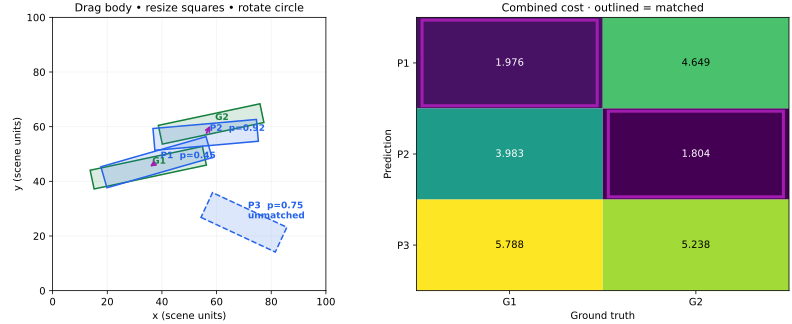

In [2]:
from IPython.display import HTML, SVG, display

from ml_sandbox.matcher_lab import (
    CostTerm,
    MatcherConfig,
    Metric,
    evaluate_costs,
    solve_assignment,
)
from ml_sandbox.matcher_lab.presets import baseline, scene_presets
from ml_sandbox.matcher_lab.visualization import pair_html, static_preview

scenes = scene_presets()
scene = scenes["Neighboring text lines"]
config = baseline()
display(SVG(static_preview(scene, config)))

Green rectangles are ground truth; blue rectangles are predictions.
Magenta arrows and outlined matrix cells show the **same global assignment**. Dashed boxes
are unmatched. Rows are predictions and columns are targets. A zero-overlap pair can still
be assigned: the solver chooses exactly `min(number of predictions, number of targets)` pairs.

For a concrete confidence tradeoff, use the scene below: P1 has perfect localization but
confidence 0.08; P2 is displaced but has confidence 0.98. The baseline weights geometry enough
to prefer P1. Classification alone prefers P2. These are different objectives, not solver errors.

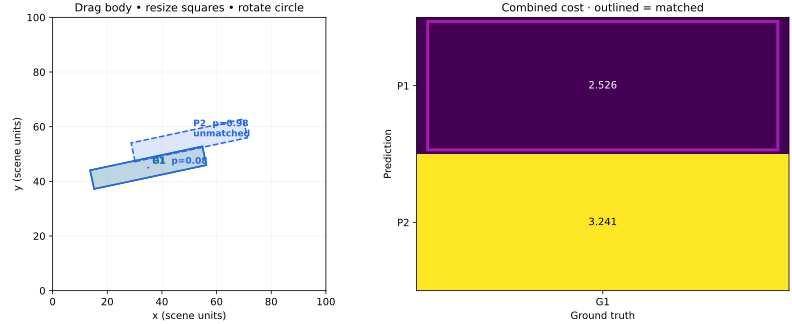

Metric,Raw,Cost,Weighted
L1,0,0,0
Rotated IoU,1,0,0
ProbIoU,1,disabled,0
Hausdorff,0,disabled,0
p (foreground),0.08,2.52573,2.52573


Metric,Raw,Cost,Weighted
L1,0.25,0.25,1.25
Rotated IoU,0.014692,0.985308,1.97062
ProbIoU,0.106908,disabled,0
Hausdorff,0.180278,disabled,0
p (foreground),0.98,0.0202027,0.0202027


In [3]:
tradeoff = scenes["Confidence versus localization"]
geometry_config = baseline()
confidence_config = MatcherConfig((CostTerm(Metric.CLASSIFICATION, 1.0),))
geometry_evaluation = evaluate_costs(tradeoff.predictions, tradeoff.targets, geometry_config)
confidence_evaluation = evaluate_costs(tradeoff.predictions, tradeoff.targets, confidence_config)
assert solve_assignment(geometry_evaluation.total).pairs == ((0, 0),)
assert solve_assignment(confidence_evaluation.total).pairs == ((1, 0),)
display(SVG(static_preview(tradeoff, geometry_config)))
display(HTML(pair_html(tradeoff, geometry_config, geometry_evaluation, "P1", "G1")))
display(HTML(pair_html(tradeoff, geometry_config, geometry_evaluation, "P2", "G1")))

## What enters the matrix?

The explicit Phase 1 baseline is classification × 1 + normalized L1 × 5 + rotated IoU cost × 2.
It is an OBB prototype baseline; standard DETR uses GIoU in its geometry sum. GIoU is deferred.

$$C_{ij}=\sum_k\lambda_k C_k(P_i,G_j),\qquad
\min_{\text{one-to-one pairs}}\sum_{(i,j)}C_{ij}.$$

The notebook keeps the combination and solver call visible:

In [4]:
evaluation = evaluate_costs(scene.predictions, scene.targets, config)
combined_cost = sum(
    (component.weighted for component in evaluation.components),
    start=evaluation.total * 0,
)
assert (combined_cost == evaluation.total).all()
assignment = solve_assignment(combined_cost)
assert len(assignment.pairs) == min(len(scene.predictions), len(scene.targets))
assert len({i for i, _ in assignment.pairs}) == len(assignment.pairs)
assert len({j for _, j in assignment.pairs}) == len(assignment.pairs)

**L1** sums center and local side-length differences, divided by explicit x/y scene
scales. The default scales are 100 and do not change with zoom. An optional angle term uses the
shortest orientation difference modulo $\pi$, divided by $\pi$; its default weight is zero.
Swapping width and height plus a quarter turn represents the same rectangle but can change
parameter L1. Rotated IoU and Gaussian ProbIoU respect that equivalent geometry.

**Rotated IoU** uses the actual polygon intersection, including rotated corners. **ProbIoU**
represents an OBB with a normalized Gaussian distribution:

$$\Sigma=R_\theta\operatorname{diag}(w^2,h^2)R_\theta^\mathsf{T}/12,\quad
D_B=\tfrac18\Delta c^\mathsf{T}\bar\Sigma^{-1}\Delta c+
\tfrac12\log\frac{\det\bar\Sigma}{\sqrt{\det\Sigma_P\det\Sigma_G}},\quad
S_{\mathrm{ProbIoU}}=1-\sqrt{1-e^{-D_B}}.$$

The implementation evaluates the Gaussian distance with Cholesky solves and computes the
similarity without subtractive cancellation. Finite precision can still underflow at extreme
separation; the configurable epsilon is an explicit floor for logarithmic costs.

Both similarities offer `1 − S` or `−log(max(S, ε))`. L1 remains an unbounded distance.
Classification always uses `−log(max(p, ε))`. With one foreground class, classification is
constant across a row: it can decide which predictions remain unmatched when P > G, but cannot
change a square assignment by itself. The two transforms and alternative weights can change
the global assignment when other components are combined.

Sources: [ProbIoU paper](https://arxiv.org/abs/2106.06072) and
[SciPy rectangular assignment documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html).

## Hausdorff geometry-only matching (WACV 2025)

Choose **Geometry only: Hausdorff** in the live editor. The **Hausdorff points** control
selects 4 corners, 8 corners plus edge midpoints, or 32 boundary samples (8 per edge).
Each direction measures the farthest sampled point's distance to its nearest sample
on the other box. The symmetric distance takes the larger directional result:

$$D_H(A,B)=\max\left(\max_{a\in A}\min_{b\in B}\|a-b\|_2,
                          \max_{b\in B}\min_{a\in A}\|a-b\|_2\right).$$

This is a distance: zero is an identical sampled shape, lower is better, and there
is no upper bound or similarity transformation. Classification is disabled in this
preset. Sampling approximates boundary Hausdorff distance; increasing the point count
can change the cost in either direction. The default four-point mode matches the paper.

Normalization follows RHINO: divide cx/w by **x scale**, cy/h by **y scale**, keep the
angle, then construct the boundary points. Defaults are 100 for both scales. Unequal
scales differ from scaling already-rotated world-space corners. The pair inspector's raw
Hausdorff value is this normalized distance; weight is applied separately.

The constructed **Oversized competing prediction** scene illustrates our screenshot
finding. Compare geometry-only ProbIoU with geometry-only Hausdorff on the same scene.
The saved diagram below uses Hausdorff. In the live editor, vary point count and then
move P1 across the neighboring text lines. A single worst-covered endpoint can dominate
Hausdorff, so test several scenes before deciding that its assignments are preferable.

[Paper §3.4 and sampling ablation](https://arxiv.org/html/2305.07598v5) ·
[Official cost implementation](https://github.com/SIAnalytics/RHINO/blob/main/mmrotate/models/task_modules/assigners/match_cost.py)

This tests one geometric matching term; the full RHINO matcher also includes classification
and KLD. Adaptive denoising and regression-loss changes are outside this experiment.

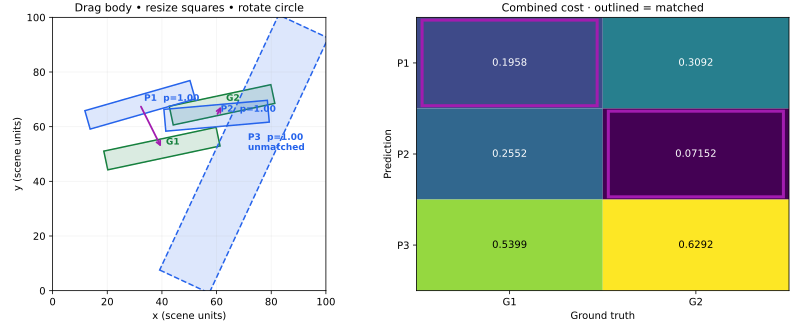

Metric,Raw,Cost,Weighted
L1,0.26,disabled,0
Rotated IoU,0,disabled,0
ProbIoU,6.19728e-05,disabled,0
Hausdorff,0.195765,0.195765,0.195765
p (foreground),1,disabled,0


In [5]:
hausdorff_scene = scenes["Oversized competing prediction"]
hausdorff_config = MatcherConfig((CostTerm(Metric.HAUSDORFF, 1.0),), hausdorff_points=4)
hausdorff_evaluation = evaluate_costs(
    hausdorff_scene.predictions, hausdorff_scene.targets, hausdorff_config
)
assert solve_assignment(hausdorff_evaluation.total).pairs == ((0, 0), (1, 1))
probiou_config = MatcherConfig((CostTerm(Metric.PROBIOU, 1.0),))
probiou_evaluation = evaluate_costs(
    hausdorff_scene.predictions, hausdorff_scene.targets, probiou_config
)
assert solve_assignment(probiou_evaluation.total).pairs == ((1, 1), (2, 0))
display(SVG(static_preview(hausdorff_scene, hausdorff_config)))
display(HTML(pair_html(hausdorff_scene, hausdorff_config, hausdorff_evaluation, "P1", "G1")))

## One controlled experiment

1. Select **Confidence versus localization**. Keep the initial geometry fixed.
2. Disable L1 and rotated IoU. Classification alone selects high-confidence P2.
3. Restore **Reset baseline**. Check which weighted geometry costs overcome that confidence advantage.
4. Try **Class + ProbIoU**, then switch its similarity transform. Inspect both pairs rather than
   comparing totals across different cost definitions as though their scales were identical.
5. With **Neighboring text lines**, move P2 vertically through the gap. Observe the assignment
   boundary and inspect the matrix on each side. A small perturbation can change the global
   optimum even though each cost is continuous.

Matching is a diagnostic of the chosen objective. More intuitive or stable assignments do not
by themselves establish better final detection accuracy.

Phase 2 will add continuous fields, additional geometric metrics, and simultaneous matcher
comparison. Phase 3 will add perturbation sweeps, Monte Carlo diagnostics, and scene export.
These features are intentionally absent from this validated Phase 1 prototype.